# Breast mass classification: balancing detection and false alarms
## A reproducible student data science portfolio project

**Question:** How well can measurements of cell nuclei distinguish malignant from benign breast masses, and how does the classification threshold change missed malignancies and false alarms?

I compare a majority-class baseline with linear, nonlinear, and tree-based classifiers, then develop an interpretable logistic regression model. The emphasis is on a defensible evaluation workflow, not just a high accuracy score. Malignant is the positive class (`1`).

**Scope:** This is retrospective classification of a small benchmark of sampled breast masses, not population screening, future cancer-risk prediction, or a clinically validated diagnostic tool. No treatment recommendations follow from this analysis.

**Reading guide:** data provenance and checks → training-only exploration → model comparison → threshold selection → locked test evaluation → interpretation and limitations. Run all cells in order; results and the executive summary are computed rather than manually transcribed.

## 1. Reproducibility and data provenance
The Wisconsin Diagnostic Breast Cancer dataset contains 569 observations and 30 numeric predictors derived from digitized fine-needle aspirate images. Scikit-learn bundles the dataset, so this notebook needs no upload, credentials, or network access after dependencies are installed.

Install `numpy pandas matplotlib seaborn scikit-learn ipython` in your notebook environment. Exact execution versions are printed below. The seed is fixed; versions and numerical libraries can still affect results.

Sources: [UCI dataset and definitions](https://archive.ics.uci.edu/dataset/17/breast-cancer-wisconsin-diagnostic), [scikit-learn loader](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html). The original supplied notebook expected a separate CSV; its contents were not supplied here. This revision explicitly uses the canonical bundled dataset rather than claiming to verify that CSV.

In [1]:
import sys
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix, ConfusionMatrixDisplay,
    RocCurveDisplay, PrecisionRecallDisplay, classification_report)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 12)
print("Python:", sys.version.split()[0])
for package in ["numpy", "pandas", "matplotlib", "seaborn", "scikit-learn"]:
    print(f"{package}: {version(package)}")

Python: 3.14.4
numpy: 2.5.4
pandas: 3.1.1
matplotlib: 3.11.2
seaborn: 0.13.2
scikit-learn: 1.9.1


In [2]:
data = load_breast_cancer(as_frame=True)
X = data.data.copy()
# Loader encodes malignant=0, benign=1. Deliberately reverse this.
y = (data.target == 0).astype(int).rename("malignant")
assert list(data.target_names) == ["malignant", "benign"]
assert X.shape == (569, 30)
assert np.isfinite(X.to_numpy()).all()
assert set(y.unique()) == {0, 1}
print(f"Observations: {len(X)} | Predictors: {X.shape[1]} | Missing values: {X.isna().sum().sum()}")
print("Duplicate feature rows:", int(X.duplicated().sum()))
assert not X.duplicated().any(), "Investigate duplicates before splitting"
print(y.value_counts().rename(index={0: "Benign", 1: "Malignant"}))
display(X.head())

Observations: 569 | Predictors: 30 | Missing values: 0
Duplicate feature rows: 0
malignant
Benign       357
Malignant    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,...,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,...,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,...,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,...,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,...,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,...,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Each of ten characteristics (size, texture, and shape) has a **mean**, **standard error**, and **worst** summary. Worst means the mean of the three largest values, not the three lowest values. Standard error should not be described as interchangeable with standard deviation. Identifiers are absent from this loader and are not predictors. There are no missing measurements to impute. Extreme values are retained because the available metadata does not establish that they are recording errors.

## 2. Reserve the test set before exploration
A stratified 80/20 split preserves class proportions approximately. All exploratory comparisons and development decisions below use the training portion only. The test set is opened after the model, regularization, and decision threshold are fixed. This is an internal random split, not evidence of transfer to other hospitals or populations.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
assert set(X_train.index).isdisjoint(X_test.index)
print(f"Training: {len(X_train)} | Held-out test: {len(X_test)}")
train = X_train.assign(diagnosis=y_train.map({0: "Benign", 1: "Malignant"}))
display(pd.DataFrame({"count": train.diagnosis.value_counts(),
                      "proportion": train.diagnosis.value_counts(normalize=True)}))

Training: 455 | Held-out test: 114


,count,proportion
diagnosis,,
Benign,285,0.626374
Malignant,170,0.373626


## 3. Explore separability and redundancy
I inspect representative features from all three summary families. Class overlap matters: a difference in averages does not mean a feature can classify every observation. Correlation identifies redundant measurements, not causes of malignancy.

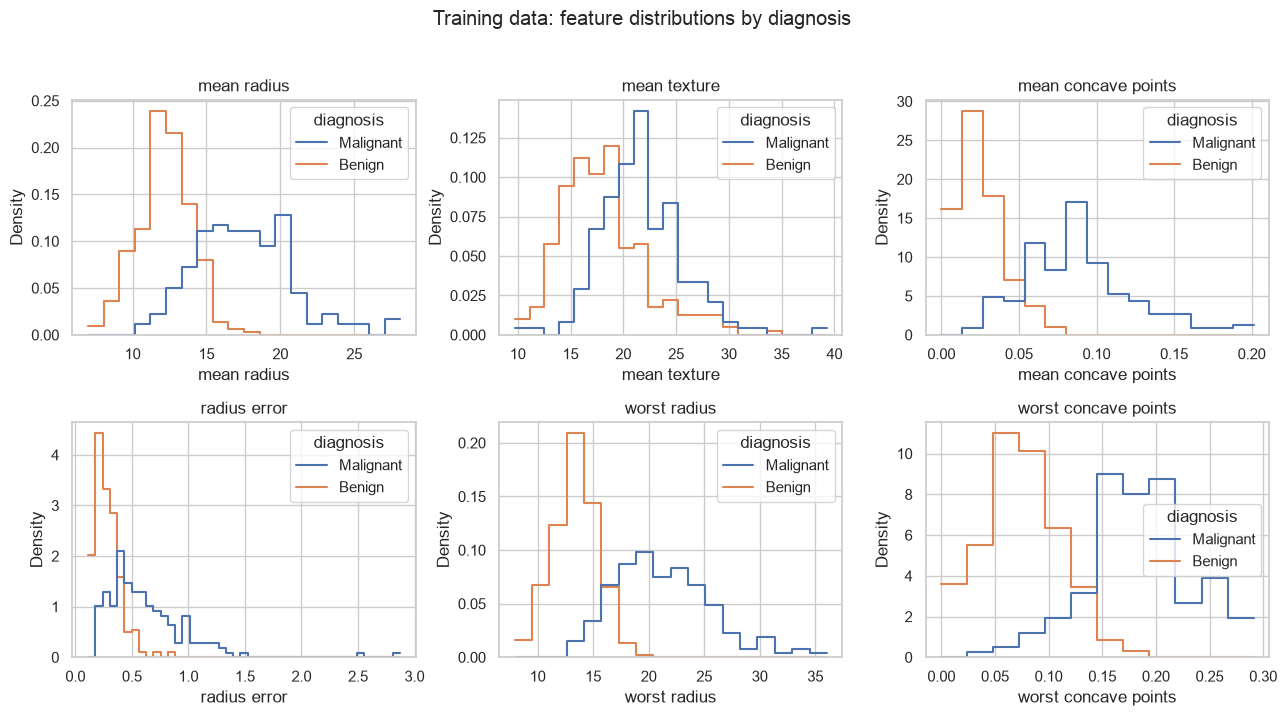

diagnosis,Benign,Malignant
mean radius,12.210,17.385
mean texture,17.530,21.520
mean concave points,0.023,0.086
radius error,0.259,0.547
worst radius,13.350,20.850
worst concave points,0.074,0.183


In [4]:
selected = ["mean radius", "mean texture", "mean concave points",
            "radius error", "worst radius", "worst concave points"]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.flat, selected):
    sns.histplot(data=train, x=col, hue="diagnosis", stat="density",
                 common_norm=False, element="step", fill=False, ax=ax)
    ax.set_title(col)
fig.suptitle("Training data: feature distributions by diagnosis", y=1.02)
plt.tight_layout(); plt.show()
display(train.groupby("diagnosis", observed=True)[selected].median().T.round(3))

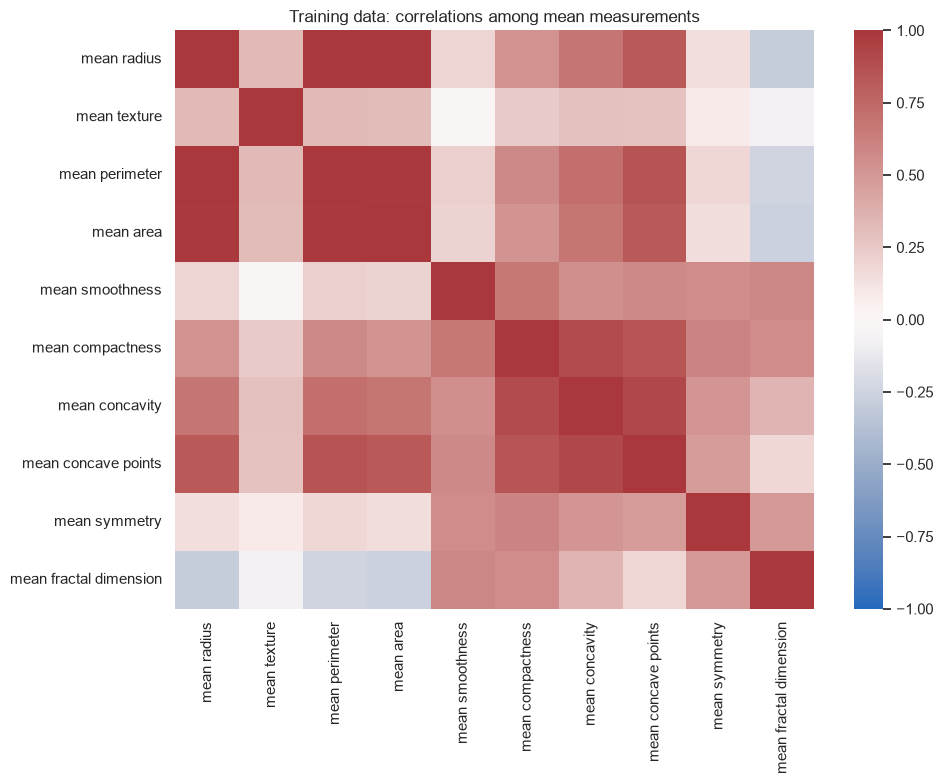

Pearson r
mean radius    mean perimeter        0.997815
               mean area             0.986740
mean perimeter mean area             0.985960
mean concavity mean concave points   0.920598

In [5]:
mean_features = [c for c in X.columns if c.startswith("mean ")]
corr = X_train[mean_features].corr()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Training data: correlations among mean measurements")
plt.tight_layout(); plt.show()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
display(upper.loc[upper.abs() > .9].sort_values(ascending=False).rename("Pearson r").to_frame())

**Interpretation:** Size and boundary-shape measurements can separate the classes, but their distributions overlap. Radius, perimeter, and area carry overlapping size information. I retain all predictors and use regularization rather than selecting features from test outcomes. Correlation can make individual coefficient or permutation rankings unstable; low importance does not establish biological irrelevance.

## 4. Compare complementary techniques
Five-fold stratified cross-validation uses only the training set. Scaling sits inside each pipeline so validation folds do not influence fitted means or variances. The models demonstrate a baseline, regularized linear classification, an RBF support-vector machine, and an ensemble of decision trees.

ROC-AUC measures ranking; average precision summarizes the precision–recall curve and depends on prevalence. Recall measures detected malignancies, while specificity measures correctly rejected benign masses. Accuracy alone obscures the trade-off. All threshold-based comparison metrics below use each estimator's default decision rule. Fold standard deviations describe variation, not confidence intervals.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
models = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
    "RBF SVM": make_pipeline(StandardScaler(), SVC(random_state=RANDOM_STATE)),
    "Random forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1),
}
scoring = {"accuracy": "accuracy", "recall": "recall", "roc_auc": "roc_auc",
           "average_precision": "average_precision"}
rows = []
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, error_score="raise")
    row = {"model": name}
    for metric in scoring:
        row[metric + " mean"] = scores["test_" + metric].mean()
        row[metric + " sd"] = scores["test_" + metric].std(ddof=1)
    rows.append(row)
comparison = pd.DataFrame(rows).set_index("model").sort_values("roc_auc mean", ascending=False)
display(comparison.round(3))

,accuracy mean,accuracy sd,recall mean,recall sd,roc_auc mean,roc_auc sd,average_precision mean,average_precision sd
model,,,,,,,,
Logistic regression,0.974,0.017,0.953,0.045,0.996,0.005,0.995,0.005
RBF SVM,0.971,0.006,0.947,0.038,0.995,0.006,0.994,0.005
Random forest,0.960,0.018,0.935,0.044,0.988,0.008,0.987,0.008
Majority baseline,0.626,0.000,0.000,0.000,0.500,0.000,0.374,0.000


## 5. Develop an interpretable model and select a threshold
I develop logistic regression for its simplicity and inspectable standardized coefficients; this is a deliberate modeling choice, not a claim that it wins every benchmark metric. A small grid selects regularization strength using training CV ROC-AUC.

Threshold policy is specified before examining the test set: **among out-of-fold training thresholds achieving at least 95% malignant recall, maximize specificity**, breaking ties with the highest threshold. The 95% target is an illustrative project objective, not an established clinical requirement. It exposes the trade-off without assigning an unsupported monetary cost to errors.

The out-of-fold predictions below keep each row out of its fitting fold, but the regularization parameter was selected using the same overall training set. Therefore these development estimates are not an unbiased nested-CV performance estimate. Only the untouched test set is used for the final reported check.

Selected regularization: {'logisticregression__C': 1}
Development CV AUC (selection estimate): 0.996


Locked threshold: 0.5088


,Out-of-fold development result
threshold,0.5088
recall,0.9529
specificity,0.9860
precision,0.9759
false_negatives,8.0000
false_positives,4.0000


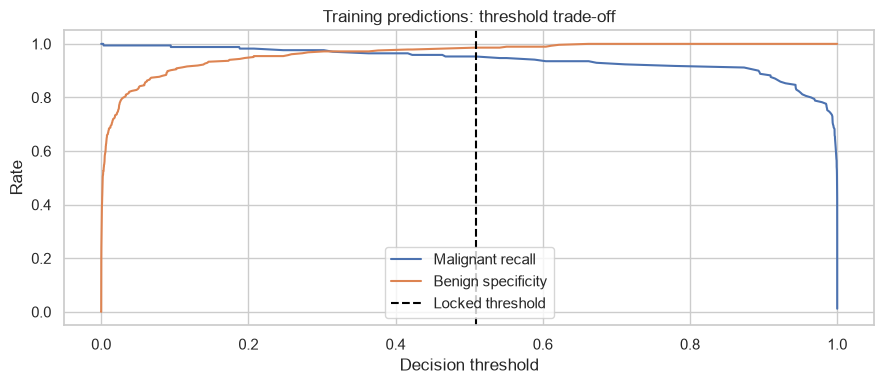

In [7]:
grid = GridSearchCV(models["Logistic regression"],
                    {"logisticregression__C": [0.01, 0.1, 1, 10, 100]},
                    scoring="roc_auc", cv=cv, n_jobs=1, error_score="raise")
grid.fit(X_train, y_train)
best = grid.best_estimator_
print("Selected regularization:", grid.best_params_)
print(f"Development CV AUC (selection estimate): {grid.best_score_:.3f}")
oof_proba = cross_val_predict(best, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

def operating_metrics(truth, prediction):
    tn, fp, fn, tp = confusion_matrix(truth, prediction, labels=[0, 1]).ravel()
    return {"recall": tp / (tp + fn), "specificity": tn / (tn + fp),
            "precision": precision_score(truth, prediction, zero_division=0),
            "false_negatives": int(fn), "false_positives": int(fp)}

threshold_rows = []
for threshold in np.unique(np.r_[0., oof_proba, 1.]):
    threshold_rows.append({"threshold": threshold,
                          **operating_metrics(y_train, oof_proba >= threshold)})
threshold_table = pd.DataFrame(threshold_rows)
eligible = threshold_table.loc[threshold_table.recall >= .95]
chosen = eligible.sort_values(["specificity", "threshold"], ascending=False).iloc[0]
locked_threshold = float(chosen.threshold)
print(f"Locked threshold: {locked_threshold:.4f}")
display(chosen.to_frame("Out-of-fold development result").round(4))
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(threshold_table.threshold, threshold_table.recall, label="Malignant recall")
ax.plot(threshold_table.threshold, threshold_table.specificity, label="Benign specificity")
ax.axvline(locked_threshold, color="black", linestyle="--", label="Locked threshold")
ax.set(xlabel="Decision threshold", ylabel="Rate", title="Training predictions: threshold trade-off")
ax.legend(); plt.tight_layout(); plt.show()

## 6. Evaluate the locked workflow on held-out observations
Both the default 0.5 rule and the training-selected threshold are reported transparently. They are not candidates to reselect using test outcomes. ROC-AUC and average precision use probabilities and do not change with the classification threshold. A recall target achieved during development may fail on held-out data.

,recall,specificity,precision,false_negatives,false_positives
rule,,,,,
Default 0.5,0.929,0.986,0.975,3,1
Training-selected threshold,0.929,0.986,0.975,3,1


Test ROC-AUC: 0.996 | Average precision: 0.994
              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



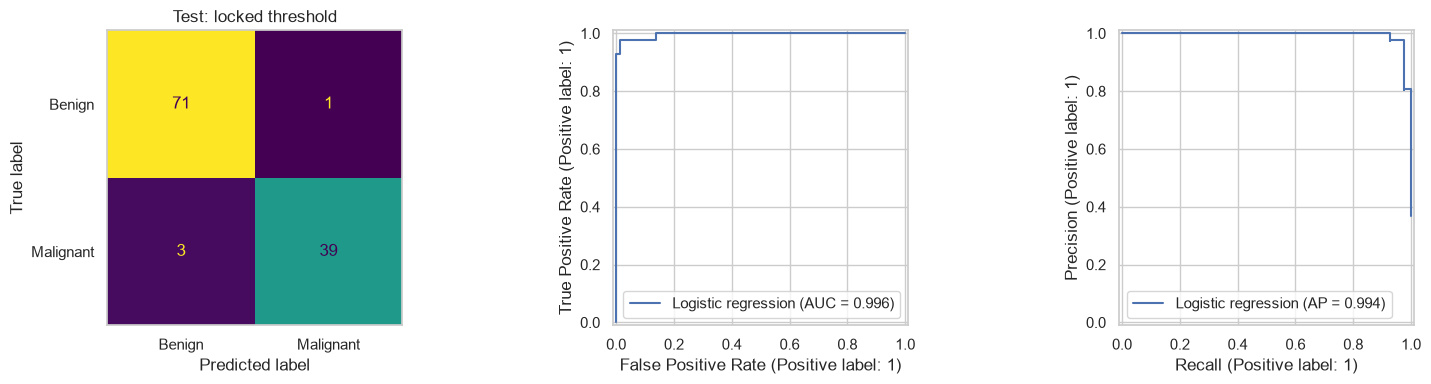

In [8]:
test_proba = best.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= locked_threshold).astype(int)
locked = operating_metrics(y_test, test_pred)
default = operating_metrics(y_test, test_proba >= .5)
auc = roc_auc_score(y_test, test_proba)
ap = average_precision_score(y_test, test_proba)
display(pd.DataFrame([{"rule": "Default 0.5", **default},
                      {"rule": "Training-selected threshold", **locked}]).set_index("rule").round(3))
print(f"Test ROC-AUC: {auc:.3f} | Average precision: {ap:.3f}")
print(classification_report(y_test, test_pred, labels=[0, 1],
                            target_names=["Benign", "Malignant"], zero_division=0))
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, labels=[0, 1],
    display_labels=["Benign", "Malignant"], colorbar=False, ax=axes[0])
axes[0].set_title("Test: locked threshold")
axes[0].grid(False)
RocCurveDisplay.from_predictions(y_test, test_proba, ax=axes[1])
PrecisionRecallDisplay.from_predictions(y_test, test_proba, ax=axes[2])
axes[1].legend([f"Logistic regression (AUC = {auc:.3f})"], loc="lower right")
axes[2].legend([f"Logistic regression (AP = {ap:.3f})"], loc="lower left")
plt.tight_layout(); plt.show()

### How uncertain is recall?
A Wilson 95% interval quantifies binomial sampling uncertainty for held-out malignant recall. It does not account for model selection, dataset bias, or distribution shift. With only a few dozen malignant test observations, one additional error materially changes the estimate.

In [9]:
def wilson_interval(successes, total, z=1.959963984540054):
    p = successes / total
    denom = 1 + z*z/total
    center = (p + z*z/(2*total)) / denom
    half = z*np.sqrt(p*(1-p)/total + z*z/(4*total*total)) / denom
    return center-half, center+half
n_malignant = int(y_test.sum())
tp = n_malignant - locked["false_negatives"]
recall_low, recall_high = wilson_interval(tp, n_malignant)
print(f"Detected {tp}/{n_malignant} malignancies; recall 95% Wilson interval: "
      f"[{recall_low:.3f}, {recall_high:.3f}]")

Detected 39/42 malignancies; recall 95% Wilson interval: [0.810, 0.975]


## 7. Interpret model behavior
Standardized logistic coefficients describe conditional associations in this fitted model; they do not identify causes. Permutation importance measures the decrease in test ROC-AUC when one feature is shuffled. This is a post-evaluation diagnostic only: no features or model settings are changed in response. Correlated predictors can substitute for one another, understating individual importance; repeat-to-repeat spread is not a confidence interval.

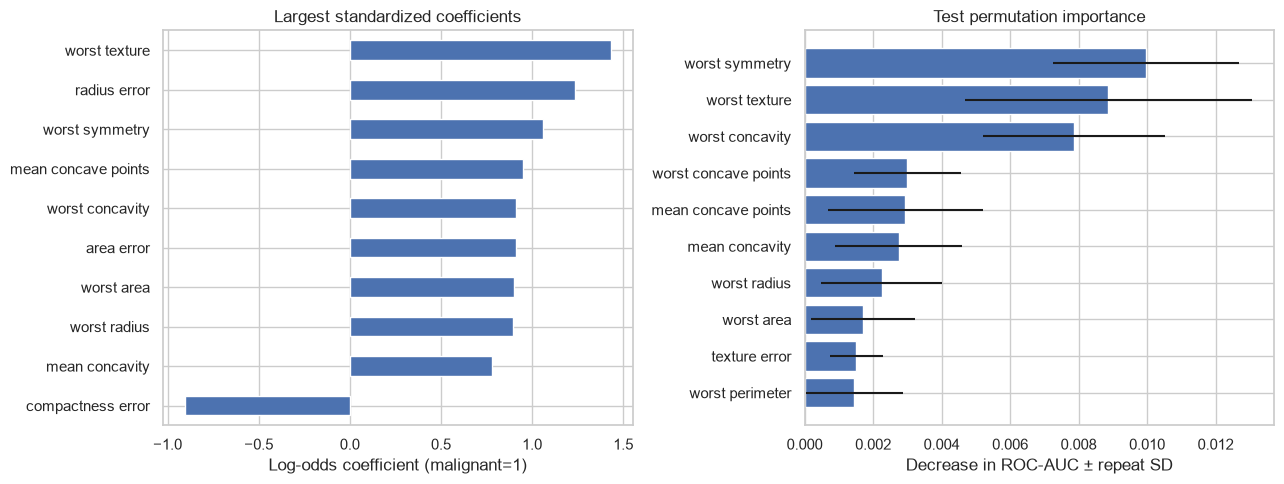

,mean AUC decrease,repeat sd
worst symmetry,0.0100,0.0027
worst texture,0.0089,0.0042
worst concavity,0.0079,0.0027
worst concave points,0.0030,0.0016
mean concave points,0.0029,0.0023
mean concavity,0.0027,0.0019
worst radius,0.0022,0.0018
worst area,0.0017,0.0015
texture error,0.0015,0.0008
worst perimeter,0.0015,0.0014


In [10]:
coefficients = pd.Series(best.named_steps["logisticregression"].coef_[0], index=X.columns)
coefficient_top = coefficients.loc[coefficients.abs().nlargest(10).index].sort_values()
imp = permutation_importance(best, X_test, y_test, scoring="roc_auc", n_repeats=20,
                             random_state=RANDOM_STATE, n_jobs=1)
importance = pd.DataFrame({"mean AUC decrease": imp.importances_mean,
                           "repeat sd": imp.importances_std}, index=X.columns)
importance = importance.sort_values("mean AUC decrease", ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
coefficient_top.plot.barh(ax=axes[0])
axes[0].set(title="Largest standardized coefficients", xlabel="Log-odds coefficient (malignant=1)")
top = importance.head(10).iloc[::-1]
axes[1].barh(top.index, top["mean AUC decrease"], xerr=top["repeat sd"])
axes[1].set(title="Test permutation importance", xlabel="Decrease in ROC-AUC ± repeat SD")
plt.tight_layout(); plt.show()
display(importance.head(10).round(4))

## 8. Executive summary and conclusions
The following summary is generated from this run so it stays aligned with the displayed results.

In [11]:
leader = comparison.index[0]
top_features = ", ".join(importance.head(3).index)
target_result = "met" if locked["recall"] >= .95 else "did not meet"
display(Markdown(f"""
**Answer to the project question.** The measured features provide substantial discrimination in this internal split: logistic regression achieved a held-out ROC-AUC of **{auc:.3f}** and average precision of **{ap:.3f}**. This is benchmark performance, not proof of clinical utility.

- **Comparison:** {leader} had the highest mean development CV ROC-AUC ({comparison.iloc[0]['roc_auc mean']:.3f}). Logistic regression was developed for interpretability, not presented as an automatic winner.
- **Detection:** At the training-selected threshold of **{locked_threshold:.4f}**, the model detected **{tp} of {n_malignant}** malignant observations (recall **{locked['recall']:.1%}**, Wilson 95% interval **{recall_low:.1%}–{recall_high:.1%}**). It {target_result} the illustrative 95% target on the test set.
- **Trade-off:** The locked rule produced **{locked['false_negatives']} missed malignancies** and **{locked['false_positives']} benign false alarms**, compared with **{default['false_negatives']}** and **{default['false_positives']}** at 0.5. Specificity was **{locked['specificity']:.1%}**. These observed counts show why accuracy alone is insufficient.
- **Interpretation:** The three highest mean permutation-importance features were **{top_features}**. These are model associations affected by correlated predictors, not independent biological explanations.

**What this demonstrates:** data validation, exploratory visualization, correlation analysis, leakage-aware preprocessing, stratified cross-validation, baseline comparison, regularization tuning, out-of-fold threshold selection, uncertainty reporting, and model interpretation.
"""))


**Answer to the project question.** The measured features provide substantial discrimination in this internal split: logistic regression achieved a held-out ROC-AUC of **0.996** and average precision of **0.994**. This is benchmark performance, not proof of clinical utility.

- **Comparison:** Logistic regression had the highest mean development CV ROC-AUC (0.996). Logistic regression was developed for interpretability, not presented as an automatic winner.
- **Detection:** At the training-selected threshold of **0.5088**, the model detected **39 of 42** malignant observations (recall **92.9%**, Wilson 95% interval **81.0%–97.5%**). It did not meet the illustrative 95% target on the test set.
- **Trade-off:** The locked rule produced **3 missed malignancies** and **1 benign false alarms**, compared with **3** and **1** at 0.5. Specificity was **98.6%**. These observed counts show why accuracy alone is insufficient.
- **Interpretation:** The three highest mean permutation-importance features were **worst symmetry, worst texture, worst concavity**. These are model associations affected by correlated predictors, not independent biological explanations.

**What this demonstrates:** data validation, exploratory visualization, correlation analysis, leakage-aware preprocessing, stratified cross-validation, baseline comparison, regularization tuning, out-of-fold threshold selection, uncertainty reporting, and model interpretation.


### Limitations and next steps
- **Small retrospective benchmark:** This collection does not establish representativeness of current patients or institutions. A random internal split cannot measure external validity. No patient identifiers are available here to verify independence across people or repeated sampling.
- **Restricted inputs:** These are engineered measurements from aspirate images, not raw images, demographics, screening histories, or longitudinal outcomes. Subgroup fairness cannot be assessed from the supplied features.
- **Selection uncertainty:** Model comparisons and tuning share development folds; a nested evaluation would better quantify selection effects. The test set is used once for the fixed workflow, but this single split remains variable.
- **Probabilities and prevalence:** Probabilities have not been validated for calibration. Precision and predictive value can change with case mix and prevalence. The threshold is an illustrative operating choice, not a medical recommendation.
- **Next steps:** evaluate on an independently collected cohort, use nested development evaluation, inspect calibration with training-only calibration procedures, and define an externally justified error trade-off before any prospective evaluation. Do not keep adjusting the workflow to improve this test score.

### Portfolio review: what changed
1. **Purpose and intent:** replaced the scaffold and analogies with a precise classification question, audience, evaluation objective, and scope.
2. **Technique breadth:** retained complementary model families and added a complete reproducible workflow, threshold policy, and uncertainty estimate rather than adding algorithms without a purpose.
3. **Clear insights:** replaced TODO conclusions with computed metrics, error counts, ranked features, and qualified interpretations. Corrected the “worst” feature definition and removed the implication that permutation importance resolves correlation bias.

### References
- [UCI: Wisconsin Diagnostic Breast Cancer dataset](https://archive.ics.uci.edu/dataset/17/breast-cancer-wisconsin-diagnostic)
- [Scikit-learn: dataset loader and label encoding](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html)
- [Scikit-learn: avoiding data leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage)
- [Scikit-learn: decision threshold tuning](https://scikit-learn.org/stable/modules/classification_threshold.html)
- [Scikit-learn: permutation importance and correlated features](https://scikit-learn.org/stable/modules/permutation_importance.html)